# Japan 2023: Electricity Generation by Prefecture, PyPSA vs METI

This notebook compares the **annual electricity generation per prefecture and per source** of the PyPSA-Earth Japan 2023 network with the official statistics of **METI (Electric Power Survey Statistics, 2023)**.

**Inputs**

| What | File |
|---|---|
| PyPSA network (2023, 100 clusters, hourly) | `resources/elec_s_100_ec_lv1_Co2L-1h.nc` |
| Prefecture boundaries (47 prefectures) | `data/japan/japan_prefectures_2023.geojson` |
| METI 2023 generation per prefecture | `data/japan/METI_Generation_2023.xlsx` (sheet `2023_Annual`) |

**Outputs** (written to `results/japan_prefecture_validation/`)

- `prefecture_generation_comparison_2023.csv`: per prefecture and source
- `region_generation_comparison_2023.csv`: per region and source
- figures (`*.png`)

**Method in short**

1. Every network bus (cluster node) is assigned to **one** prefecture, based on where the bus is located.
2. All generation at that bus is counted for that prefecture.
3. PyPSA carriers are mapped to METI categories and compared.

> The clusters do not follow prefecture borders. A cluster can cover parts of several prefectures, but all its generation is counted in the prefecture where its bus sits. The more nodes the network has, the more accurate this gets.

Run the notebook from the repository root.

## 1. Load the network and assign each bus to a prefecture

- Only the **grid buses (AC/DC)** are used for the spatial match. The H2 and battery buses sit at the same locations and get the prefecture of their grid bus via the `location` column.
- `sjoin_nearest` is used: a bus inside a prefecture gets that prefecture; a bus slightly outside (on the coast or in the sea) gets the **nearest** prefecture.
- The checks at the end list buses that were snapped to the nearest prefecture and **prefectures that have no bus at all**. Those prefectures will show 0 generation in the model.

In [1]:
import pypsa
import geopandas as gpd
import pandas as pd

# -----------------------------
# 1. Load the 2023 Japan network (100 nodes)
# -----------------------------
network = pypsa.Network("resources/elec_s_100_ec_lv1_Co2L-1h.nc")

# -----------------------------
# 2. Read prefecture shapes
# -----------------------------
pref = gpd.read_file("data/japan/japan_prefectures_2023.geojson")

# -----------------------------
# 3. Take only the grid buses (AC/DC)
#    H2 and battery buses sit at the same locations, they get handled in step 5
# -----------------------------
grid_buses = network.buses.query("carrier in ['AC', 'DC']")

bus_gdf = gpd.GeoDataFrame(
    grid_buses[["x", "y"]],
    geometry=gpd.points_from_xy(grid_buses.x, grid_buses.y),
    crs="EPSG:4326",
)

# -----------------------------
# 4. Assign each bus to a prefecture
#    bus inside a prefecture  -> that prefecture (distance 0)
#    bus just outside (coast) -> nearest prefecture
#    Metric CRS so that distances are in metres
# -----------------------------
metric_crs = "EPSG:6933"
joined = gpd.sjoin_nearest(
    bus_gdf.to_crs(metric_crs),
    pref[["prefecture", "geometry"]].to_crs(metric_crs),
    how="left",
    distance_col="dist_m",
)
joined = joined[~joined.index.duplicated()]  # a bus exactly on a border can match twice

bus_to_pref = joined["prefecture"]

# -----------------------------
# 5. Give H2 / battery buses the prefecture of their grid bus (same location)
# -----------------------------
network.buses["prefecture"] = network.buses.index.map(bus_to_pref)
loc_pref = network.buses.loc[grid_buses.index, "prefecture"]
other = network.buses["prefecture"].isna()
network.buses.loc[other, "prefecture"] = network.buses.loc[other, "location"].map(loc_pref)

# -----------------------------
# 6. Checks
# -----------------------------
print("Grid buses:", len(grid_buses))
print("Buses without prefecture:", network.buses["prefecture"].isna().sum())

print("\nBuses outside every prefecture (snapped to nearest):")
print(joined.loc[joined["dist_m"] > 0, ["prefecture", "dist_m"]].round(0))

buses_per_pref = bus_to_pref.value_counts()
print("\nGrid buses per prefecture:")
print(buses_per_pref.to_string())

missing_prefs = sorted(set(pref["prefecture"]) - set(buses_per_pref.index))
print(f"\nPrefectures with NO bus ({len(missing_prefs)}):", missing_prefs)

INFO:pypsa.io:Imported network elec_s_100_ec_lv1_Co2L-1h.nc has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores


/home/goli-vamsi-priya/miniconda3/envs/pypsa-earth/lib/python3.11/site-packages/pyogrio/__init__.py:7: DeprecationWarning: The 'shapely.geos' module is deprecated, and will be removed in a future version. All attributes of 'shapely.geos' are available directly from the top-level 'shapely' namespace (since shapely 2.0.0).
  import shapely.geos  # noqa: F401


Grid buses: 100
Buses without prefecture: 0

Buses outside every prefecture (snapped to nearest):
       prefecture  dist_m
Bus                      
JP0 14       Oita   220.0
JP0 19     Aomori  5569.0
JP8 0       Ehime  3092.0

Grid buses per prefecture:
prefecture
Niigata      5
Aomori       5
Iwate        4
Miyagi       4
Shizuoka     3
Nagano       3
Chiba        3
Shimane      3
Akita        3
Mie          3
Hyogo        3
Hokkaido     3
Yamagata     3
Fukushima    3
Wakayama     3
Kagoshima    3
Saitama      2
Ehime        2
Gifu         2
Kyoto        2
Saga         2
Kumamoto     2
Miyazaki     2
Yamaguchi    2
Ibaraki      2
Fukui        2
Gunma        2
Aichi        2
Tochigi      2
Yamanashi    2
Oita         2
Hiroshima    2
Toyama       2
Osaka        1
Tottori      1
Kagawa       1
Kochi        1
Fukuoka      1
Tokyo        1
Kanagawa     1
Tokushima    1
Shiga        1
Nara         1
Okayama      1
Okinawa      1

Prefectures with NO bus (2): ['Ishikawa', 'Nagasaki']


## 2. Model generation per prefecture and source

- Annual generation = dispatch summed over all hours × snapshot weightings.
- Storage units (hydro, PHS): only discharge (positive dispatch) counts as generation.
- `load shedding` is removed; it is not real generation.
- PyPSA carriers are mapped to METI categories:

| PyPSA carrier | METI category |
|---|---|
| CCGT, coal, oil | thermal |
| nuclear | nuclear |
| hydro, ror, PHS | hydro (METI hydro includes pumped storage) |
| onwind, offwind-ac, offwind-dc | wind |
| solar | solar |
| geothermal | geothermal |

In [2]:
# -----------------------------
# 1. Annual generation per generator / storage unit (MWh)
#    multiply by snapshot weightings (=1 for hourly, but keeps it correct)
# -----------------------------
w = network.snapshot_weightings.generators

gen_mwh = network.generators_t.p.mul(w, axis=0).sum()
gen_df = pd.DataFrame({
    "bus": network.generators.bus,
    "carrier": network.generators.carrier,
    "MWh": gen_mwh,
})

# storage units: only count discharge (positive p) as generation
sto_dispatch = network.storage_units_t.p.clip(lower=0).mul(w, axis=0).sum()
sto_df = pd.DataFrame({
    "bus": network.storage_units.bus,
    "carrier": network.storage_units.carrier,
    "MWh": sto_dispatch,
})

model = pd.concat([gen_df, sto_df])
model = model[model["carrier"] != "load shedding"]

# -----------------------------
# 2. Add prefecture of each unit (from its bus)
# -----------------------------
model["prefecture"] = model["bus"].map(network.buses["prefecture"])
print("Units without prefecture:", model["prefecture"].isna().sum())

# -----------------------------
# 3. Map PyPSA carriers -> METI categories
# -----------------------------
carrier_map = {
    "CCGT": "thermal",
    "coal": "thermal",
    "oil": "thermal",
    "nuclear": "nuclear",
    "hydro": "hydro",
    "ror": "hydro",
    "PHS": "hydro",          # METI hydro includes pumped storage
    "onwind": "wind",
    "offwind-ac": "wind",
    "offwind-dc": "wind",
    "solar": "solar",
    "geothermal": "geothermal",
}

unmapped = set(model["carrier"]) - set(carrier_map)
print("Carriers not mapped (check!):", unmapped)

model["meti_carrier"] = model["carrier"].map(carrier_map)

# -----------------------------
# 4. Sum per prefecture and METI carrier (GWh)
# -----------------------------
model_pref = (
    model.groupby(["prefecture", "meti_carrier"])["MWh"].sum().div(1e3)
    .unstack(fill_value=0)
)
model_pref.columns.name = None

# -----------------------------
# 5. Checks
# -----------------------------
print("\nModel total per carrier (TWh):")
print((model.groupby("carrier")["MWh"].sum() / 1e6).round(1).to_string())
print("\nModel total per METI category (TWh):")
print((model_pref.sum() / 1e3).round(1).to_string())
print("\nModel total (TWh):", round(model_pref.values.sum() / 1e3, 1))

print("\nPer prefecture (GWh), first rows:")
print(model_pref.round(0).head(10))

Units without prefecture: 0
Carriers not mapped (check!): set()

Model total per carrier (TWh):
carrier
CCGT          207.9
PHS             0.0
coal          356.2
geothermal      0.6
hydro          39.7
nuclear        85.4
offwind-ac      4.4
offwind-dc      0.0
oil             3.6
onwind         86.5
ror             2.2
solar         181.1

Model total per METI category (TWh):
geothermal      0.6
hydro          41.8
nuclear        85.4
solar         181.1
thermal       567.7
wind           90.9

Model total (TWh): 967.6

Per prefecture (GWh), first rows:
            geothermal   hydro  nuclear   solar  thermal     wind
prefecture                                                       
Aichi              0.0   575.0      0.0  8858.0  36783.0     11.0
Akita            392.0     0.0      0.0   220.0  12049.0   1190.0
Aomori             0.0     0.0      0.0  2897.0      5.0  20668.0
Chiba              0.0   206.0      0.0  9568.0  82911.0   2654.0
Ehime              0.0     0.0   5835.0  

## 3. METI reference data

- Source: METI Electric Power Survey Statistics, sheet `2023_Annual`. Unit in the file is 1,000 kWh (= MWh), converted to GWh.
- **Important: METI "thermal" already includes biomass and waste.** The sheet total is `hydro + thermal + nuclear + (wind + solar + geothermal) + others`, so biomass and waste are not separate additions.
- The PyPSA model has no biomass or waste plants, so they are **subtracted from METI thermal**, and we compare **fossil thermal only**.
- Because of this, the compared METI total is **790.5 TWh** instead of the 822.7 TWh in the Excel sheet (biomass 27.9 + waste 4.0 + others 0.2 TWh are left out).

In [3]:
# -----------------------------
# 1. Read METI 2023 annual generation per prefecture
#    unit in file: 1,000 kWh (= MWh)
# -----------------------------
meti_raw = pd.read_excel(
    "data/japan/METI_Generation_2023.xlsx", sheet_name="2023_Annual"
)
meti_raw = meti_raw.rename(columns={"prefectures": "prefecture"})
meti_raw["prefecture"] = meti_raw["prefecture"].astype(str).str.strip()

# drop the national "total" row
meti_raw = meti_raw[meti_raw["prefecture"].str.lower() != "total"]

# -----------------------------
# 2. Rename METI columns to the same categories used for the model
# -----------------------------
meti_cols = {
    "hydroelectric power plant": "hydro",
    "thermal power plant": "thermal",
    "nuclear power plant": "nuclear",
    "wind power": "wind",
    "sunlight": "solar",
    "geothermal": "geothermal",
    "biomass": "biomass",
    "Waste": "waste",
}
meti_pref = meti_raw.set_index("prefecture")[list(meti_cols)].rename(columns=meti_cols)
meti_pref = meti_pref.astype(float) / 1e3  # MWh -> GWh

# -----------------------------
# 3. METI "thermal" ALREADY INCLUDES biomass and waste
#    (sheet total = hydro + thermal + nuclear + wind/solar/geo + others)
#    The model has no biomass/waste -> compare model thermal with FOSSIL thermal only
# -----------------------------
meti_pref["thermal"] = meti_pref["thermal"] - meti_pref["biomass"] - meti_pref["waste"]
meti_pref = meti_pref.drop(columns=["biomass", "waste"])

# -----------------------------
# 4. Checks: 47 prefectures, names match the geojson
# -----------------------------
print("METI prefectures:", len(meti_pref))
print("Names in METI but not in geojson:", sorted(set(meti_pref.index) - set(pref["prefecture"])))
print("Names in geojson but not in METI:", sorted(set(pref["prefecture"]) - set(meti_pref.index)))
print("\nMETI total per category (TWh), thermal = fossil only:")
print((meti_pref.sum() / 1e3).round(1).to_string())
print("METI total (TWh):", round(meti_pref.values.sum() / 1e3, 1))

METI prefectures: 47
Names in METI but not in geojson: []
Names in geojson but not in METI: []

METI total per category (TWh), thermal = fossil only:
hydro          80.7
thermal       598.8
nuclear        77.5
wind            8.0
solar          23.5
geothermal      2.0
METI total (TWh): 790.5


## 4. Comparison table

One row per prefecture and source (47 × 6 = 282 rows), with:

- `PyPSA_GWh`, `METI_GWh`
- `diff_GWh` = PyPSA − METI
- `diff_pct` = difference in % of METI (empty when METI is 0)
- `has_bus`: False for prefectures without any bus in the model

In [4]:
import os

# -----------------------------
# 1. Long format: one row per prefecture + category
# -----------------------------
categories = ["thermal", "nuclear", "hydro", "solar", "wind", "geothermal"]
all_prefs = sorted(pref["prefecture"])  # all 47, also the ones without a bus

model_long = (
    model_pref.reindex(index=all_prefs, columns=categories, fill_value=0)
    .stack().rename("PyPSA_GWh")
)
meti_long = (
    meti_pref.reindex(index=all_prefs, columns=categories, fill_value=0)
    .stack().rename("METI_GWh")
)

comparison = pd.concat([model_long, meti_long], axis=1)
comparison.index.names = ["prefecture", "carrier"]
comparison = comparison.reset_index()

# -----------------------------
# 2. Differences
# -----------------------------
comparison["diff_GWh"] = comparison["PyPSA_GWh"] - comparison["METI_GWh"]
comparison["diff_pct"] = (
    comparison["diff_GWh"] / comparison["METI_GWh"].where(comparison["METI_GWh"] > 0) * 100
)
comparison["has_bus"] = comparison["prefecture"].isin(bus_to_pref.unique())

# -----------------------------
# 3. Save
# -----------------------------
os.makedirs("results/japan_prefecture_validation", exist_ok=True)
out = "results/japan_prefecture_validation/prefecture_generation_comparison_2023.csv"
comparison.round(2).to_csv(out, index=False)
print("Saved:", out, "| rows:", len(comparison))

# -----------------------------
# 4. Quick look
# -----------------------------
national = comparison.groupby("carrier")[["PyPSA_GWh", "METI_GWh"]].sum() / 1e3
national["diff_pct"] = (national["PyPSA_GWh"] / national["METI_GWh"] - 1) * 100
print("\nNational totals (TWh):")
print(national.round(1))

totals = comparison.groupby("prefecture")[["PyPSA_GWh", "METI_GWh"]].sum()
totals["diff_GWh"] = totals["PyPSA_GWh"] - totals["METI_GWh"]
print("\nPrefecture totals, biggest gaps (GWh):")
print(totals.reindex(totals["diff_GWh"].abs().sort_values(ascending=False).index).round(0).head(10))

Saved: results/japan_prefecture_validation/prefecture_generation_comparison_2023.csv | rows: 282

National totals (TWh):
            PyPSA_GWh  METI_GWh  diff_pct
carrier                                  
geothermal        0.6       2.0     -71.8
hydro            41.8      80.7     -48.2
nuclear          85.4      77.5      10.3
solar           181.1      23.5     669.4
thermal         567.7     598.8      -5.2
wind             90.9       8.0    1038.8

Prefecture totals, biggest gaps (GWh):
            PyPSA_GWh  METI_GWh  diff_GWh
prefecture                               
Tokyo         76844.0    5380.0   71465.0
Kanagawa      28644.0   71952.0  -43308.0
Kyoto         54202.0   11681.0   42521.0
Miyagi        50659.0   12889.0   37770.0
Saga          53048.0   18332.0   34716.0
Fukui         22618.0   49906.0  -27288.0
Fukushima     27262.0   52451.0  -25189.0
Toyama        37505.0   14087.0   23418.0
Nagasaki          0.0   21366.0  -21366.0
Aomori        23570.0    4617.0   18953.0

## 5. Plots

### 5.1 National totals per source

A sanity check before looking at prefectures: if a source is already off at the national level, it will be off in every prefecture too.

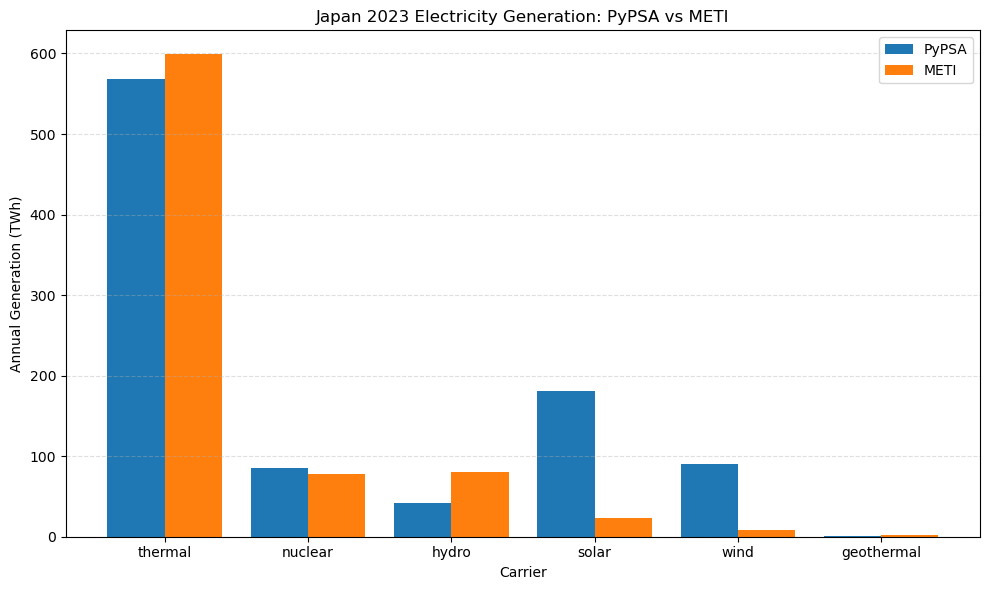

In [5]:
import matplotlib.pyplot as plt
import numpy as np

fig_dir = "results/japan_prefecture_validation"

# -----------------------------
# 1. National totals per carrier: PyPSA vs METI (bar plot)
# -----------------------------
national = comparison.groupby("carrier")[["PyPSA_GWh", "METI_GWh"]].sum() / 1e3  # TWh
national = national.reindex(categories)

x = np.arange(len(national))
width = 0.4

plt.figure(figsize=(10, 6))
plt.bar(x - width / 2, national["PyPSA_GWh"], width, label="PyPSA")
plt.bar(x + width / 2, national["METI_GWh"], width, label="METI")

plt.xticks(x, national.index)
plt.xlabel("Carrier")
plt.ylabel("Annual Generation (TWh)")
plt.title("Japan 2023 Electricity Generation: PyPSA vs METI")
plt.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig(f"{fig_dir}/national_generation_by_carrier.png", dpi=150)
plt.show()

### 5.2 Per prefecture, one plot per source

Grey bands mark prefectures that have **no bus** in the model.

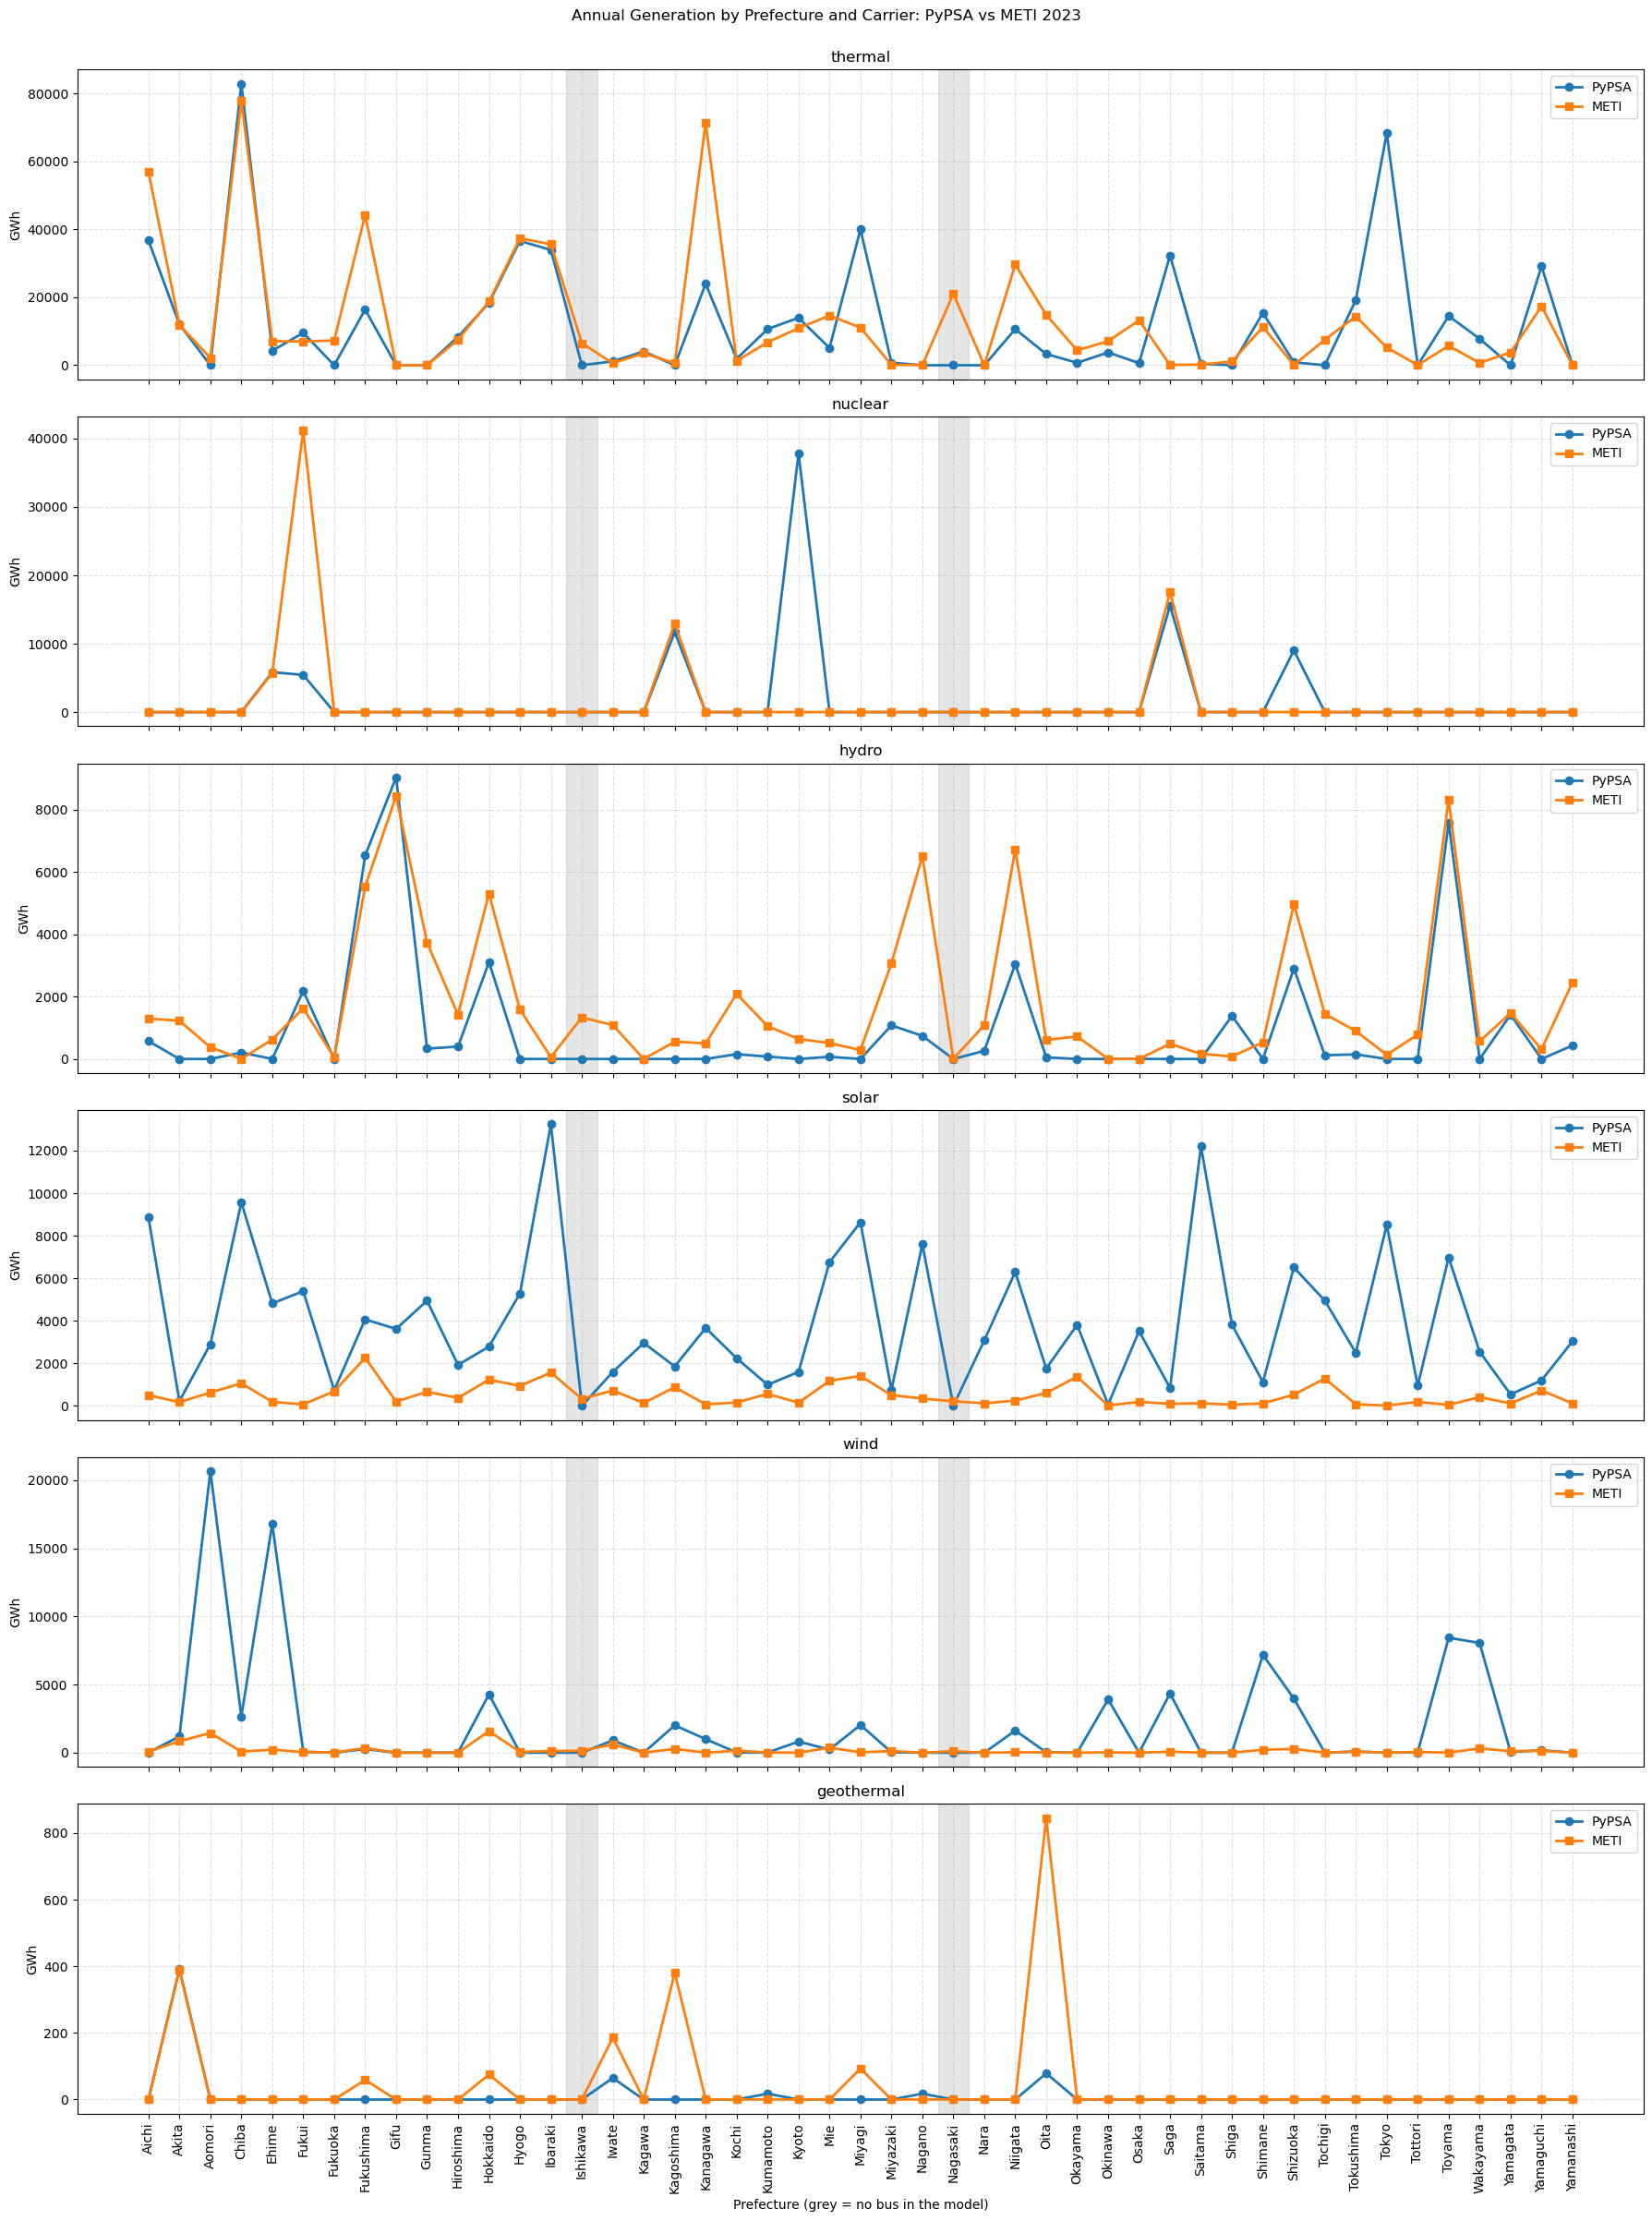

In [6]:
# -----------------------------
# 1. Per prefecture, one subplot per carrier (line plot)
# -----------------------------
fig, axes = plt.subplots(len(categories), 1, figsize=(18, 4 * len(categories)), sharex=True)

for ax, carrier in zip(axes, categories):

    df = comparison[comparison["carrier"] == carrier].sort_values("prefecture")
    x = np.arange(len(df))

    ax.plot(x, df["PyPSA_GWh"], marker="o", linewidth=2, label="PyPSA")
    ax.plot(x, df["METI_GWh"], marker="s", linewidth=2, label="METI")

    # mark prefectures without any bus in the model
    for i, has_bus in enumerate(df["has_bus"]):
        if not has_bus:
            ax.axvspan(i - 0.5, i + 0.5, color="grey", alpha=0.2)

    ax.set_title(carrier)
    ax.set_ylabel("GWh")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper right")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(df["prefecture"], rotation=90)
axes[-1].set_xlabel("Prefecture (grey = no bus in the model)")

fig.suptitle("Annual Generation by Prefecture and Carrier: PyPSA vs METI 2023", y=1.0)
plt.tight_layout()
plt.savefig(f"{fig_dir}/prefecture_generation_by_carrier.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Per prefecture, all sources together

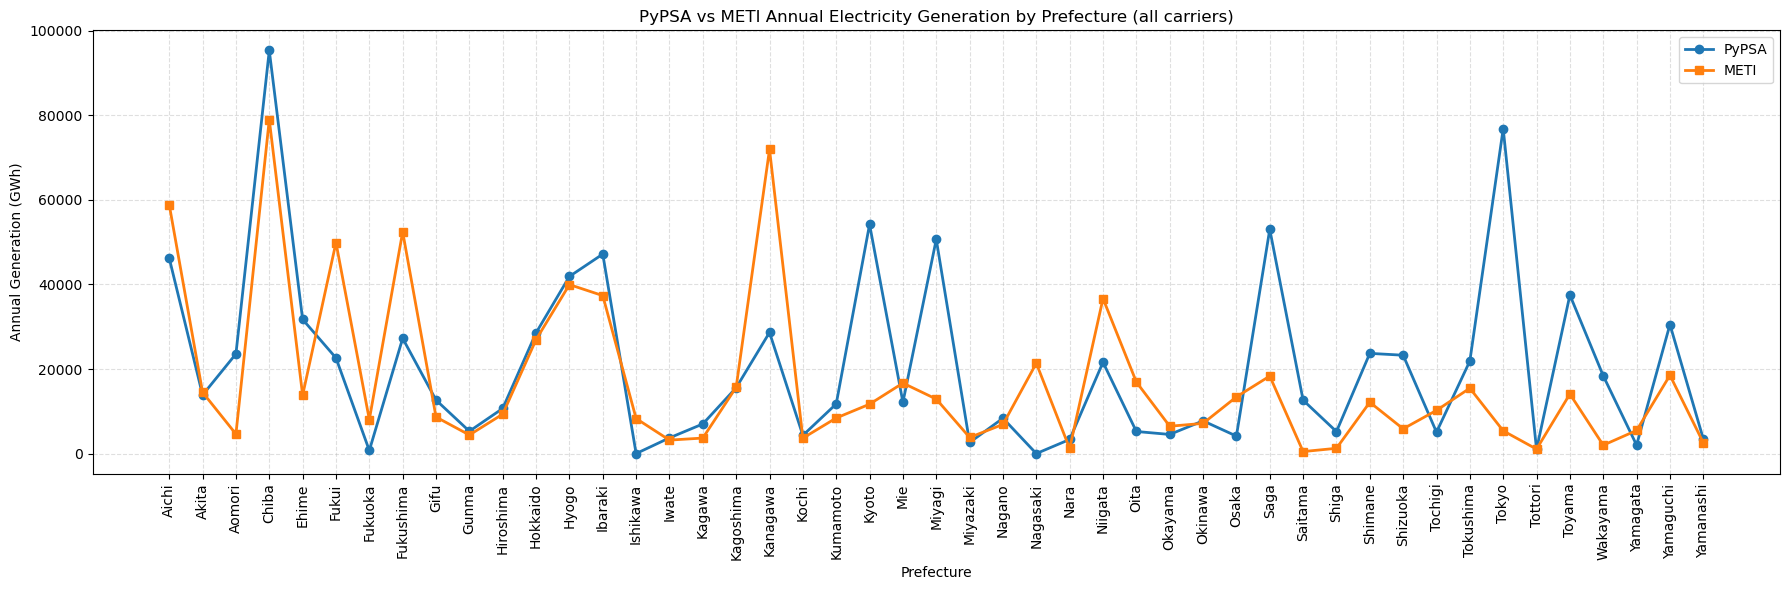

In [7]:
# -----------------------------
# 1. Per prefecture, total generation (all carriers)
# -----------------------------
totals = comparison.groupby("prefecture")[["PyPSA_GWh", "METI_GWh"]].sum().sort_index()

plt.figure(figsize=(18, 6))
plt.plot(totals.index, totals["PyPSA_GWh"], marker="o", linewidth=2, label="PyPSA")
plt.plot(totals.index, totals["METI_GWh"], marker="s", linewidth=2, label="METI")

plt.xticks(rotation=90)
plt.xlabel("Prefecture")
plt.ylabel("Annual Generation (GWh)")
plt.title("PyPSA vs METI Annual Electricity Generation by Prefecture (all carriers)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig(f"{fig_dir}/prefecture_generation_total.png", dpi=150)
plt.show()

## 6. Regional view (8 regions)

Many prefecture differences come in **pairs of neighbours**: generation that is in the model, but counted in the neighbouring prefecture because of where the cluster bus sits. Grouping prefectures into Japan's 8 standard regions shows how much of the error is only this *location* effect.

The printed "misplaced generation" is the sum of absolute differences divided by the METI total, per prefecture vs per region.

Prefectures without region: []
thermal: misplaced generation  per prefecture 65%  |  per region 15%
nuclear: misplaced generation  per prefecture 111%  |  per region 88%

Thermal + nuclear per region (GWh):
                  PyPSA_GWh  METI_GWh  diff_GWh  diff_pct
region   carrier                                         
Chubu    nuclear    14470.0   41184.0  -26715.0     -65.0
         thermal    72294.0  105956.0  -33663.0     -32.0
Chugoku  nuclear        0.0       0.0       0.0       NaN
         thermal    53632.0   40567.0   13066.0      32.0
Hokkaido nuclear        0.0       0.0       0.0       NaN
         thermal    18380.0   18761.0    -381.0      -2.0
Kansai   nuclear    37828.0       0.0   37828.0       NaN
         thermal    64075.0   77919.0  -13844.0     -18.0
Kanto    nuclear        0.0       0.0       0.0       NaN
         thermal   209587.0  197749.0   11838.0       6.0
Kyushu   nuclear    27284.0   30572.0   -3289.0     -11.0
         thermal    50782.0   57877.0  

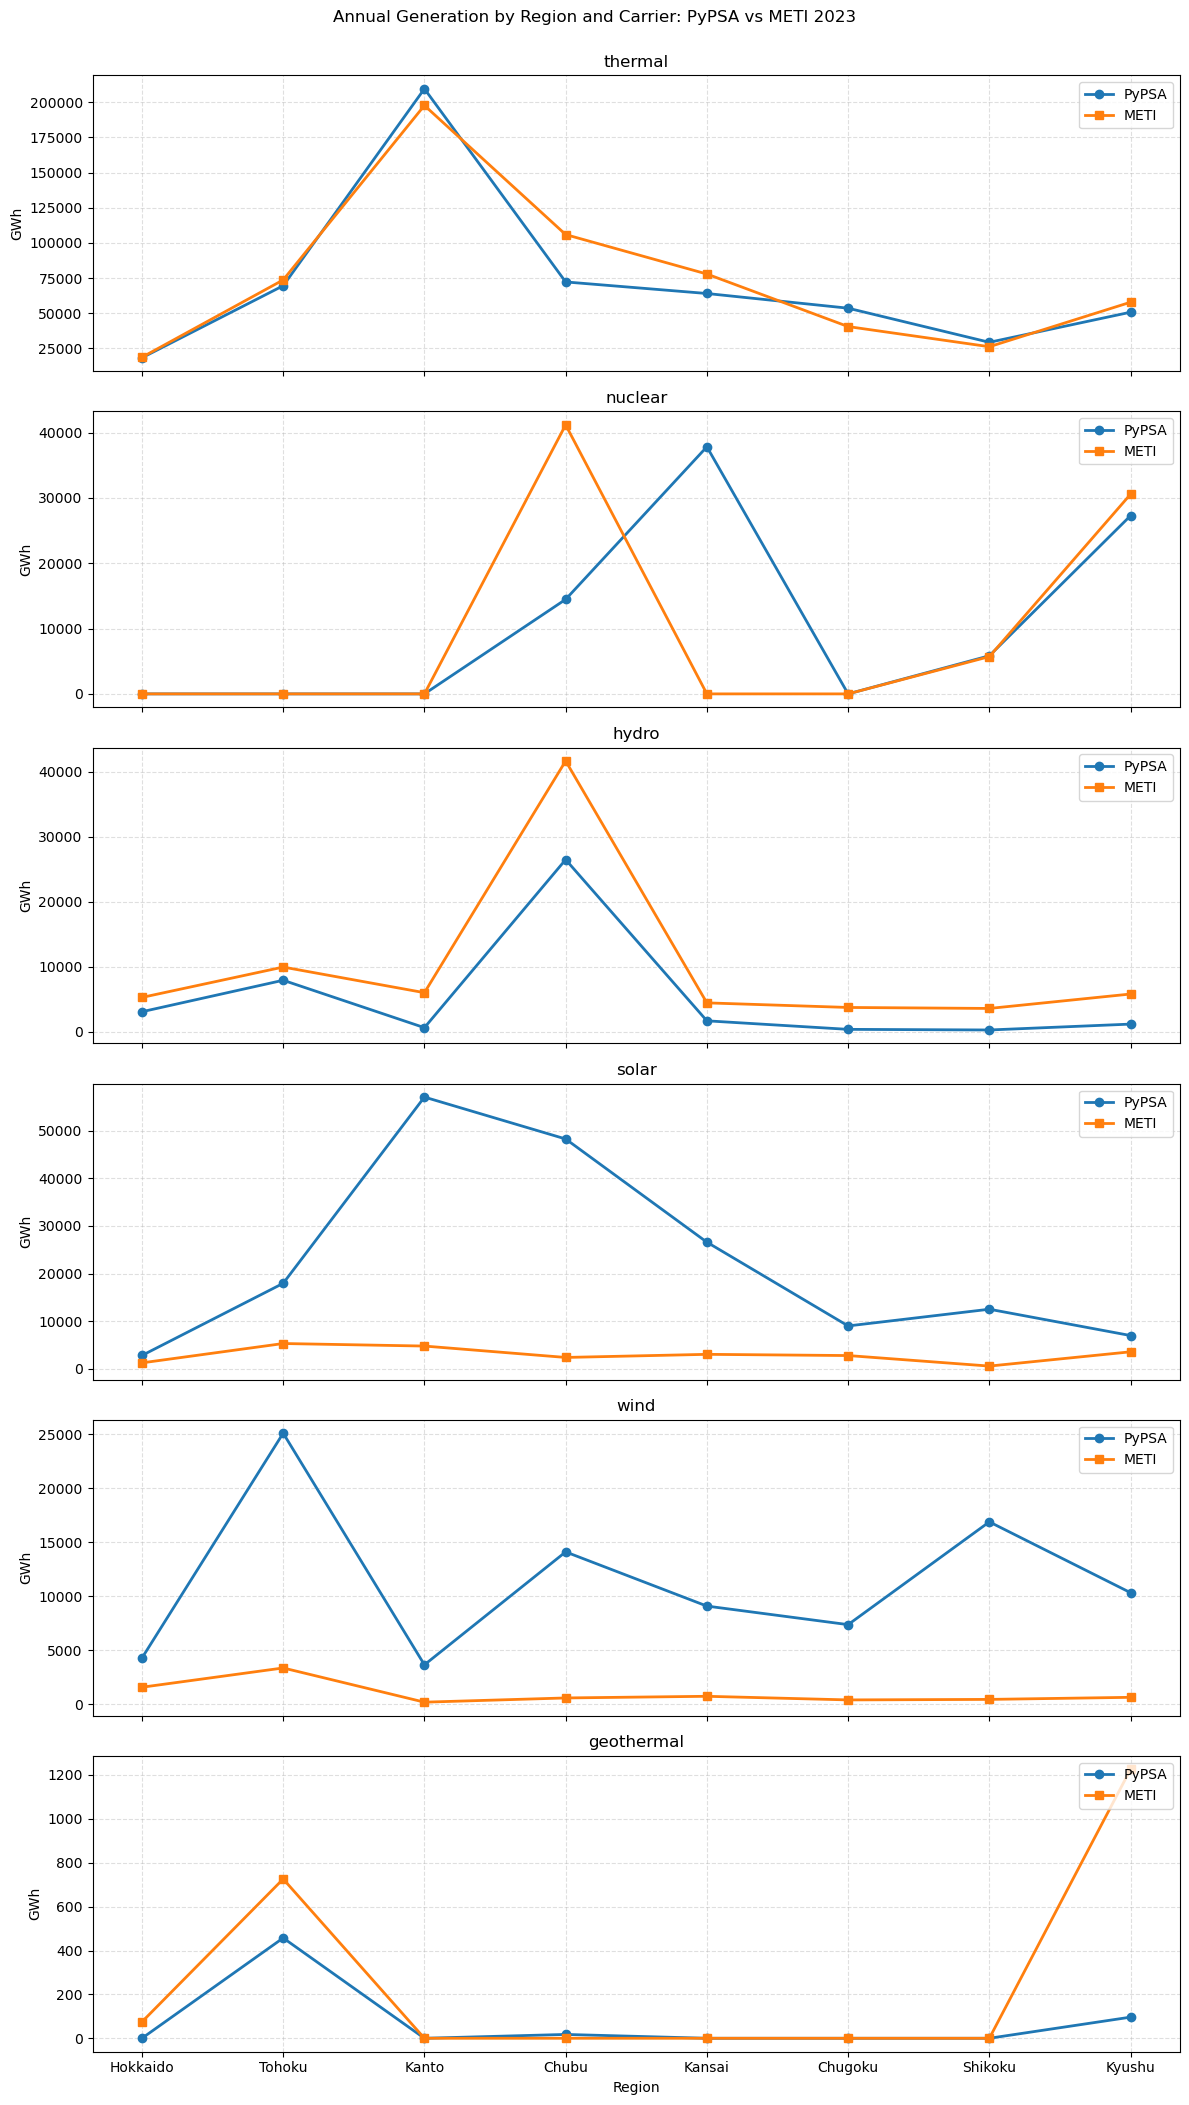

In [8]:
# -----------------------------
# 1. Prefecture -> region (8 standard regions of Japan)
# -----------------------------
regions = {
    "Hokkaido": ["Hokkaido"],
    "Tohoku": ["Aomori", "Iwate", "Miyagi", "Akita", "Yamagata", "Fukushima"],
    "Kanto": ["Ibaraki", "Tochigi", "Gunma", "Saitama", "Chiba", "Tokyo", "Kanagawa"],
    "Chubu": ["Niigata", "Toyama", "Ishikawa", "Fukui", "Yamanashi", "Nagano", "Gifu", "Shizuoka", "Aichi"],
    "Kansai": ["Mie", "Shiga", "Kyoto", "Osaka", "Hyogo", "Nara", "Wakayama"],
    "Chugoku": ["Tottori", "Shimane", "Okayama", "Hiroshima", "Yamaguchi"],
    "Shikoku": ["Tokushima", "Kagawa", "Ehime", "Kochi"],
    "Kyushu": ["Fukuoka", "Saga", "Nagasaki", "Kumamoto", "Oita", "Miyazaki", "Kagoshima", "Okinawa"],
}
pref_to_region = {p: r for r, prefs in regions.items() for p in prefs}

comparison["region"] = comparison["prefecture"].map(pref_to_region)
print("Prefectures without region:", comparison.loc[comparison["region"].isna(), "prefecture"].unique())

# -----------------------------
# 2. Sum per region and carrier
# -----------------------------
region_comp = (
    comparison.groupby(["region", "carrier"])[["PyPSA_GWh", "METI_GWh"]].sum().reset_index()
)
region_comp["diff_GWh"] = region_comp["PyPSA_GWh"] - region_comp["METI_GWh"]
region_comp["diff_pct"] = (
    region_comp["diff_GWh"] / region_comp["METI_GWh"].where(region_comp["METI_GWh"] > 0) * 100
)

region_comp.round(2).to_csv(f"{fig_dir}/region_generation_comparison_2023.csv", index=False)

# -----------------------------
# 3. Compare: how big are the errors per prefecture vs per region?
#    (thermal + nuclear, where the location matters most)
# -----------------------------
for carrier in ["thermal", "nuclear"]:
    p = comparison[comparison["carrier"] == carrier]
    r = region_comp[region_comp["carrier"] == carrier]
    share_p = p["diff_GWh"].abs().sum() / p["METI_GWh"].sum() * 100
    share_r = r["diff_GWh"].abs().sum() / r["METI_GWh"].sum() * 100
    print(f"{carrier}: misplaced generation  per prefecture {share_p:.0f}%  |  per region {share_r:.0f}%")

print("\nThermal + nuclear per region (GWh):")
print(
    region_comp[region_comp["carrier"].isin(["thermal", "nuclear"])]
    .set_index(["region", "carrier"]).round(0)
)

# -----------------------------
# 4. Plot: one subplot per carrier, regions on x-axis (line plot)
# -----------------------------
region_order = list(regions)

fig, axes = plt.subplots(len(categories), 1, figsize=(12, 3.5 * len(categories)), sharex=True)

for ax, carrier in zip(axes, categories):

    df = region_comp[region_comp["carrier"] == carrier].set_index("region").reindex(region_order)

    ax.plot(df.index, df["PyPSA_GWh"], marker="o", linewidth=2, label="PyPSA")
    ax.plot(df.index, df["METI_GWh"], marker="s", linewidth=2, label="METI")

    ax.set_title(carrier)
    ax.set_ylabel("GWh")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Region")

fig.suptitle("Annual Generation by Region and Carrier: PyPSA vs METI 2023", y=1.0)
plt.tight_layout()
plt.savefig(f"{fig_dir}/region_generation_by_carrier.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Findings

**Location effect (from clustering)**

- **Ishikawa and Nagasaki have no bus** in the 100-node network, so they show 0 generation. Their plants are counted in neighbouring prefectures (for example Nagasaki's coal in Saga).
- Large pairs of opposite differences between neighbours: **Tokyo (+) / Kanagawa (−)** (Tokyo Bay plants on the Tokyo bus), **Kyoto (+) / Fukui (−)** (Fukui nuclear plants on a Kyoto bus), **Saga (+) / Nagasaki (−)**.
- For thermal, misplaced generation drops from **65% per prefecture to 15% per region**, so most of the prefecture error is this location effect.
- For nuclear it only drops from 111% to 88%: the Fukui/Kyoto swap crosses a region border (Chubu/Kansai), and see the Hamaoka point below.
- A network with more nodes should reduce this effect.

**Model and data issues (not caused by the prefecture method)**

- **Nuclear in Shizuoka (Hamaoka, ~9 TWh)**: the model generates here, but Hamaoka has been offline since 2011 (METI: 0).
- **Wind is ~11× METI**: onshore wind is extendable in the network, and the optimiser built ~37 GW instead of the ~5 GW installed in 2023.
- **Solar is ~8× METI**: partly capacity, and possibly METI's solar column covers only power-plant scale solar (not rooftop). To check.
- **Hydro is about half of METI**. METI hydro includes pumped storage, so model PHS is counted as hydro too. Model PHS discharge is 0 TWh in 2023, so the gap comes from conventional hydro (hydro + ror).
- **Biomass and waste (~32 TWh) are missing** in the model.
- Thermal (−5%) and nuclear (+10%) are close at the national level.